# Bài toán cộng (Adding Problem): LSTM so với RNN

**Nhóm 5:** Nguyễn Phú Đại · Trần Vũ Tiến Minh · Trần Đình Hiếu · Phạm Thanh An

Notebook này sinh số liệu cho **thí nghiệm 3** của bài thuyết trình (slide 25, component `CompareChart`). Hai thí nghiệm kia nằm ở `lstm_ecommerce.ipynb` và `lstm_stock.ipynb`.

Khác với hai bộ dữ liệu của A6, đây là **dữ liệu tổng hợp** được thiết kế để có **phụ thuộc rất xa**: mô hình phải nhớ một con số qua ít nhất $T/2$ bước. Bài toán này có trong bài báo LSTM gốc (Hochreiter & Schmidhuber, 1997).

**Thiết kế để so sánh công bằng:** RNN và LSTM dùng cùng kiến trúc `RNN/LSTM(2→64)` → trạng thái ẩn ở bước cuối → `Linear(64→1)`, cùng optimizer, cùng dữ liệu (cùng seed sinh batch). Chỉ khác lớp hồi quy (`nn.RNN` hay `nn.LSTM`).

Code phần 1–3 chép từ Phần 1 của `LSTM_vs_RNN.ipynb` cũ (commit `14c8207`), để `slides/data/compare.json` sinh ra đúng như trước.

## 1. Thiết lập

Kết quả cho slide ghi vào `slides/data/compare.json` (định dạng `CompareChart` đọc). Bản tổng hợp, kèm kiểm tra thêm seed, ghi vào `experiment/results/lstm_adding.json`. Hình lưu vào `experiment/figures/`.

In [1]:
import json, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn

torch.set_num_threads(4)
SLIDES_DATA = Path('..') / 'slides' / 'data'      # notebook nằm trong thư mục experiment/
RESULTS = Path('results')
FIGURES = Path('figures')
for p in (SLIDES_DATA, RESULTS, FIGURES):
    p.mkdir(parents=True, exist_ok=True)
plt.rcParams['figure.dpi'] = 100
print('PyTorch', torch.__version__, '| numpy', np.__version__, '| pandas', pd.__version__)

PyTorch 2.14.0+cpu | numpy 2.4.6 | pandas 3.0.3


## 2. Bài toán

Mỗi mẫu là chuỗi độ dài $T$, mỗi bước gồm 2 giá trị: một số ngẫu nhiên $\sim U(0, 1)$ và một cờ 0/1. Đúng 2 vị trí có cờ 1: một ở nửa đầu, một ở nửa sau chuỗi. Mục tiêu là **tổng 2 số tại 2 vị trí đó**. Vì vị trí thứ nhất nằm ở nửa đầu, mô hình phải giữ giá trị đó qua ít nhất $T/2$ bước.

**Mức "đoán mò":** luôn dự đoán hằng số 1 (kỳ vọng của tổng) → MSE = phương sai của tổng = $2 \cdot \frac{1}{12} = \frac{1}{6} \approx 0.167$. Mô hình nào có MSE quanh 0.167 là chưa học được gì.

**Cấu hình chung:** hidden 64, Adam lr 1e-3, batch 64, 5000 bước (mỗi bước sinh một batch mới), clip gradient 1.0. So sánh $T = 10$ (phụ thuộc ngắn) và $T = 100$ (phụ thuộc xa). Tập kiểm tra cố định: 2000 mẫu sinh với seed 12345.

In [2]:
HIDDEN, BATCH, STEPS, LR, LOG_EVERY = 64, 64, 5000, 1e-3, 25
SEQ_LENS = [10, 100]

def make_batch(batch, T, gen):
    values = torch.rand(batch, T, generator=gen)
    marks = torch.zeros(batch, T)
    first = torch.randint(0, T // 2, (batch,), generator=gen)
    second = torch.randint(T // 2, T, (batch,), generator=gen)
    idx = torch.arange(batch)
    marks[idx, first] = 1.0
    marks[idx, second] = 1.0
    x = torch.stack([values, marks], dim=-1)          # (batch, T, 2)
    y = (values * marks).sum(dim=1, keepdim=True)      # (batch, 1)
    return x, y

x, y = make_batch(1, 10, torch.Generator().manual_seed(0))
print('Ví dụ một mẫu T = 10 (cột 1: giá trị, cột 2: cờ):')
print(x[0].numpy().round(3))
print('Mục tiêu y =', y.item().__round__(3))

Ví dụ một mẫu T = 10 (cột 1: giá trị, cột 2: cờ):
[[0.496 0.   ]
 [0.768 1.   ]
 [0.088 0.   ]
 [0.132 0.   ]
 [0.307 0.   ]
 [0.634 0.   ]
 [0.49  1.   ]
 [0.896 0.   ]
 [0.456 0.   ]
 [0.632 0.   ]]
Mục tiêu y = 1.258


## 3. Mô hình và vòng huấn luyện

In [3]:
class SeqModel(nn.Module):
    def __init__(self, cell, input_size=2, hidden=HIDDEN):
        super().__init__()
        rnn_cls = nn.LSTM if cell == 'lstm' else nn.RNN
        self.rnn = rnn_cls(input_size=input_size, hidden_size=hidden, batch_first=True)
        self.fc = nn.Linear(hidden, 1)

    def forward(self, x):
        output, _ = self.rnn(x)
        return self.fc(output[:, -1])                  # many-to-one: lấy bước cuối


def train_adding(cell, T, seed=0):
    torch.manual_seed(seed)
    gen = torch.Generator().manual_seed(seed)
    model = SeqModel(cell)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    loss_fn = nn.MSELoss()
    curve, window = [], []
    start = time.time()
    for step in range(1, STEPS + 1):
        x, y = make_batch(BATCH, T, gen)
        loss = loss_fn(model(x), y)
        opt.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
        window.append(loss.item())
        if step % LOG_EVERY == 0:
            curve.append([step, sum(window) / len(window)])
            window = []
    elapsed = time.time() - start
    model.eval()
    with torch.no_grad():                              # tập test cố định: 2000 mẫu
        x, y = make_batch(2000, T, torch.Generator().manual_seed(12345))
        test_mse = loss_fn(model(x), y).item()
    params = sum(p.numel() for p in model.parameters())
    print(f'{cell:4s} T={T:3d} seed={seed}  test MSE={test_mse:.4f}  params={params}  time={elapsed:.0f}s')
    return {'curve': curve, 'test_mse': test_mse, 'params': params, 'seconds': round(elapsed, 1)}

## 4. Chạy chính (seed 0) → số liệu cho slide

Đây là lần chạy mà `CompareChart` vẽ đường học.

In [4]:
adding = {'config': {'hidden': HIDDEN, 'batch': BATCH, 'steps': STEPS, 'lr': LR,
                     'optimizer': 'Adam', 'clip': 1.0, 'baseline_mse': 1 / 6},
          'runs': {}}
for T in SEQ_LENS:
    adding['runs'][str(T)] = {cell: train_adding(cell, T) for cell in ('rnn', 'lstm')}

(SLIDES_DATA / 'compare.json').write_text(json.dumps(adding, indent=1), encoding='utf-8')
print('Đã lưu', SLIDES_DATA / 'compare.json')

rnn  T= 10 seed=0  test MSE=0.0012  params=4417  time=7s


lstm T= 10 seed=0  test MSE=0.0001  params=17473  time=9s


rnn  T=100 seed=0  test MSE=0.1628  params=4417  time=42s


lstm T=100 seed=0  test MSE=0.0033  params=17473  time=46s
Đã lưu ../slides/data/compare.json


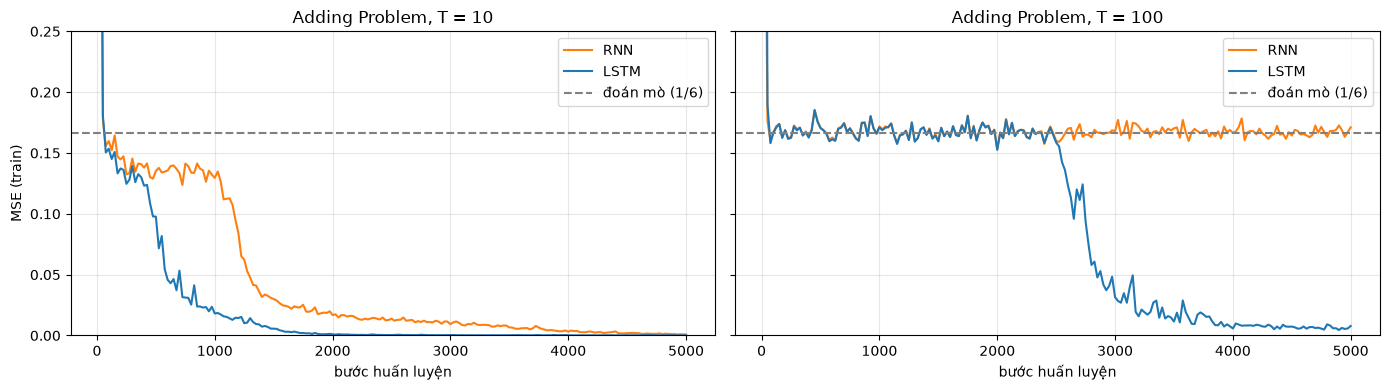

,T,mô hình,test MSE,tham số,thời gian (s)
0,10,RNN,0.0012,4417,7.4
1,10,LSTM,0.0001,17473,8.6
2,100,RNN,0.1628,4417,41.7
3,100,LSTM,0.0033,17473,46.2


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, T in zip(axes, SEQ_LENS):
    for cell, color in (('rnn', 'tab:orange'), ('lstm', 'tab:blue')):
        c = np.array(adding['runs'][str(T)][cell]['curve'])
        ax.plot(c[:, 0], c[:, 1], color=color, label=cell.upper())
    ax.axhline(1 / 6, color='grey', ls='--', label='đoán mò (1/6)')
    ax.set_title(f'Adding Problem, T = {T}'); ax.set_xlabel('bước huấn luyện'); ax.set_ylim(0, 0.25)
    ax.legend(); ax.grid(alpha=.3)
axes[0].set_ylabel('MSE (train)')
plt.tight_layout()
plt.savefig(FIGURES / 'lstm_adding_curves.png', bbox_inches='tight')
plt.show()

pd.DataFrame([{'T': T, 'mô hình': cell.upper(), 'test MSE': r['test_mse'], 'tham số': r['params'], 'thời gian (s)': r['seconds']}
              for T, d in adding['runs'].items() for cell, r in d.items()]).round(4)

## 5. Kiểm tra thêm seed

Thí nghiệm 1 và 2 chạy 5 seed. Ở đây mỗi lần chạy $T = 100$ mất khoảng nửa phút, nên chạy thêm 3 seed (1, 2, 3) để chắc kết luận của seed 0 không phải do may rủi. Chỉ ghi test MSE, không vẽ đường học.

In [6]:
EXTRA_SEEDS = [1, 2, 3]
seed_check = {str(T): {cell: {'0': adding['runs'][str(T)][cell]['test_mse']} for cell in ('rnn', 'lstm')} for T in SEQ_LENS}
for T in SEQ_LENS:
    for cell in ('rnn', 'lstm'):
        for s in EXTRA_SEEDS:
            seed_check[str(T)][cell][str(s)] = train_adding(cell, T, seed=s)['test_mse']

rows = []
for T, d in seed_check.items():
    for cell, per in d.items():
        v = np.array(list(per.values()))
        rows.append({'T': int(T), 'mô hình': cell.upper(), **{f'seed {k}': x for k, x in per.items()},
                     'trung bình': v.mean(), 'dưới mức đoán mò / 10': int((v < (1 / 6) / 10).sum())})
seed_df = pd.DataFrame(rows)
seed_df.round(4)

rnn  T= 10 seed=1  test MSE=0.0008  params=4417  time=7s


rnn  T= 10 seed=2  test MSE=0.0011  params=4417  time=7s


rnn  T= 10 seed=3  test MSE=0.0013  params=4417  time=7s


lstm T= 10 seed=1  test MSE=0.0000  params=17473  time=8s


lstm T= 10 seed=2  test MSE=0.0001  params=17473  time=8s


...

rnn  T=100 seed=3  test MSE=0.1608  params=4417  time=45s


lstm T=100 seed=1  test MSE=0.0040  params=17473  time=55s


lstm T=100 seed=2  test MSE=0.0032  params=17473  time=47s


lstm T=100 seed=3  test MSE=0.0018  params=17473  time=47s


,T,mô hình,seed 0,seed 1,seed 2,seed 3,trung bình,dưới mức đoán mò / 10
0,10,RNN,0.0012,0.0008,0.0011,0.0013,0.0011,4
1,10,LSTM,0.0001,0.0000,0.0001,0.0003,0.0001,4
2,100,RNN,0.1628,0.1626,0.1615,0.1608,0.1619,0
3,100,LSTM,0.0033,0.0040,0.0032,0.0018,0.0031,4


In [7]:
summary = {
    'config': adding['config'] | {'seq_lens': SEQ_LENS, 'main_seed': 0, 'extra_seeds': EXTRA_SEEDS, 'test_samples': 2000},
    'main': {T: {cell: {k: r[k] for k in ('test_mse', 'params', 'seconds')} for cell, r in d.items()}
             for T, d in adding['runs'].items()},
    'seed_check': seed_check,
}
(RESULTS / 'lstm_adding.json').write_text(json.dumps(summary, indent=1), encoding='utf-8')
print('Đã lưu', RESULTS / 'lstm_adding.json')

Đã lưu results/lstm_adding.json


**Nhận xét về lần chạy này**

- **Tái lập số liệu cũ.** Seed 0 cho đúng từng con số của `compare.json` cũ (sinh từ `LSTM_vs_RNN.ipynb`, commit `14c8207`): cả 4 đường học trùng khớp hoàn toàn, test MSE giống hệt. Chỉ thời gian chạy khác (máy đang tải khác lúc trước): RNN 41.7 s, LSTM 46.2 s với $T = 100$.
- **$T = 10$ (phụ thuộc ngắn): cả hai đều học được.** Test MSE của RNN ≈ 0.0011, LSTM ≈ 0.0001 (trung bình 4 seed), đều thấp hơn mức đoán mò 0.167 hàng trăm lần.
- **$T = 100$ (phụ thuộc xa): RNN không học được, LSTM học được, ở cả 4 seed.** RNN có test MSE 0.161–0.163, tức nằm đúng ở mức đoán mò 0.167. LSTM có test MSE 0.0018–0.0040 (trung bình 0.0031), thấp hơn RNN khoảng 50 lần. Seed tệ nhất của LSTM vẫn tốt hơn seed tốt nhất của RNN khoảng 40 lần.
- **Đường học của LSTM với $T = 100$** nằm ở mức đoán mò một thời gian rồi mới giảm mạnh: mô hình phải "tìm ra" cách giữ cổng quên gần 1 để mang số đầu tiên qua ≥ 50 bước. RNN không có con đường đó, nên tín hiệu lỗi từ cuối chuỗi không về tới số được đánh dấu đầu tiên.
- **Chi phí:** LSTM có 17 473 trọng số so với 4 417 của RNN (gần gấp 4) và chạy chậm hơn một chút.
